# Disaster Tweets — Text Preprocessing & Trigram N-Gram Language Model

**University NLP course project**

The goal of this project is to work with real **disaster tweets** and to demonstrate two tasks:

1. **Task 1 — Dataset selection and text preprocessing**: inspect the dataset and build a clear, reproducible preprocessing pipeline that turns raw tweets into cleaned tokens (`cleaned_text`).
2. **Task 2 — N-Gram language model**: implement a **Trigram (3-gram) model** using the Markov assumption and Maximum Likelihood Estimation (MLE), explain smoothing, and calculate the probability of **three sentences taken from the actual dataset** — step by step, with every count coming from real data.

**Dataset:** [*Disaster Tweets* (Kaggle, vstepanenko)](https://www.kaggle.com/datasets/vstepanenko/disaster-tweets).
The dataset was already downloaded; a copy of `tweets.csv` was extracted from `archive.zip` into `data/`.
The original archive is **not modified**.

**Labels** — the `target` column is binary:
* `1` = tweet refers to a real disaster (flood, earthquake, wildfire, explosion, ...)
* `0` = tweet does **not** refer to a real disaster (metaphorical or unrelated use of disaster words)

> **How to run:** execute the notebook top-to-bottom. All file paths are relative to the project folder, so the project can be moved to another machine. No package installation happens inside the notebook — required libraries are listed in `requirements.txt`.

## 1. Setup
We import all required libraries (Pandas, NumPy, NLTK, Matplotlib), set a fixed random seed for reproducibility, and configure Matplotlib for clean plots.

**Library status check** (performed before running the notebook): `pandas`, `numpy`, `nltk`, and `matplotlib` were **not all pre-installed**, so they were installed with `pip install --user pandas numpy nltk matplotlib` (checked first with a dry run). No installation is performed inside the notebook itself.

In [1]:
# ============================================================
# Section 1 — Setup, configuration and reproducibility
# ============================================================
%matplotlib inline

import math
import html
import re
import string
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.tag import pos_tag
from IPython.display import display, Markdown

# --- reproducibility --------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)   # the pipeline is fully deterministic; the seed is set anyway for good practice

# --- Matplotlib aesthetics -------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
})

# --- file paths (relative, portable) ----------------------------------
PROJECT_DIR = None
DATA_PATH = None
for candidate in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    p = candidate / "data" / "tweets.csv"
    if p.exists():
        PROJECT_DIR, DATA_PATH = candidate, p
        break
assert DATA_PATH is not None, "tweets.csv not found — expected under data/tweets.csv next to this notebook"

OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

print("Project dir :", PROJECT_DIR)
print("Dataset     :", DATA_PATH)
print("Outputs dir :", OUTPUT_DIR)
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| nltk:", nltk.__version__)

Project dir : /home/dev911/Downloads/Disaster Tweets/Disaster_Tweets_NLP
Dataset     : /home/dev911/Downloads/Disaster Tweets/Disaster_Tweets_NLP/data/tweets.csv
Outputs dir : /home/dev911/Downloads/Disaster Tweets/Disaster_Tweets_NLP/outputs
pandas: 3.1.1 | numpy: 2.4.4 | nltk: 3.10.4


## 2. Task 1A — Dataset Inspection
Before touching the text we inspect the data carefully. We **do not assume column names** — everything is verified against the real file:

1. dataset shape, column names and data types;
2. the first rows;
3. missing values per column;
4. duplicated records;
5. identification of the *text* column and the *target/label* column;
6. distribution of the target classes.

In [2]:
# ============================================================
# Section 2 — Load the dataset and inspect its structure
# ============================================================
# utf-8-sig: the CSV starts with a Byte-Order-Mark (BOM); utf-8-sig removes it cleanly
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

n_raw = len(df)
initial_target_counts = df["target"].value_counts().sort_index()

print("Dataset shape:", df.shape)
print("\nColumn names:", list(df.columns))
display(df.dtypes.to_frame("dtype"))
display(df.head(5))

# --- missing values ---------------------------------------------------
display(df.isna().sum().to_frame("missing_values"))

# --- duplicate records ------------------------------------------------
dup_full_rows = df.duplicated().sum()
dup_ids       = df["id"].duplicated().sum()
dup_texts     = df["text"].duplicated().sum()
print(f"Fully duplicated rows : {dup_full_rows}")
print(f"Duplicated ids         : {dup_ids}")
print(f"Duplicated text fields  : {dup_texts}  (same tweet text stored under different ids/keywords)")

# --- text and target columns ------------------------------------------
assert df["text"].isna().sum() == 0, "the text column must be complete"
assert set(df["target"].unique()) == {0, 1}, "target must be binary"
print("\nText column   : 'text'   (0 empty texts)")
print("Target column : 'target' (binary: 1 = real disaster, 0 = not a real disaster)")

# --- class distribution ------------------------------------------------
target_table = pd.DataFrame({
    "target": [0, 1],
    "meaning": ["Not a real disaster", "Real disaster"],
    "n_tweets": [initial_target_counts.get(0, 0), initial_target_counts.get(1, 0)],
})
target_table["proportion"] = (target_table["n_tweets"] / n_raw).round(4)
display(target_table)

Dataset shape: (11370, 5)

Column names: ['id', 'keyword', 'location', 'text', 'target']


,dtype
id,int64
keyword,str
location,str
text,str
target,int64


,id,keyword,location,text,target
0,0,ablaze,NaN,"Communal violence in Bhainsa, Telangana. ""Ston...",1
1,1,ablaze,NaN,Telangana: Section 144 has been imposed in Bha...,1
2,2,ablaze,New York City,Arsonist sets cars ablaze at dealership https:...,1
3,3,ablaze,"Morgantown, WV",Arsonist sets cars ablaze at dealership https:...,1
4,4,ablaze,NaN,"""Lord Jesus, your love brings freedom and pard...",0


,missing_values
id,0
keyword,0
location,3418
text,0
target,0


Fully duplicated rows : 0
Duplicated ids         : 0
Duplicated text fields  : 147  (same tweet text stored under different ids/keywords)

Text column   : 'text'   (0 empty texts)
Target column : 'target' (binary: 1 = real disaster, 0 = not a real disaster)


,target,meaning,n_tweets,proportion
0,0,Not a real disaster,9256,0.8141
1,1,Real disaster,2114,0.1859


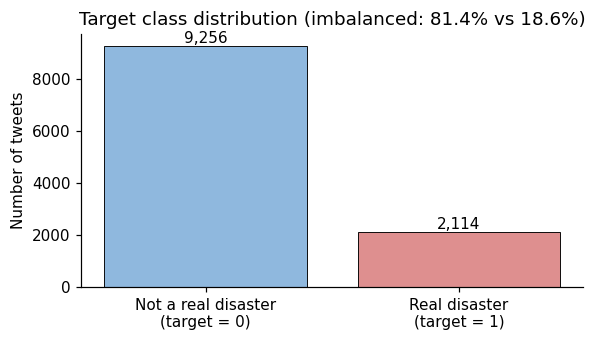

In [3]:
# --- class-distribution visualisation ---------------------------------
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(["Not a real disaster\n(target = 0)", "Real disaster\n(target = 1)"],
              [initial_target_counts.get(0, 0), initial_target_counts.get(1, 0)],
              color=["#8fb8de", "#de8f8f"], edgecolor="black", linewidth=0.6)
for b in bars:
    ax.annotate(f"{int(b.get_height()):,}", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_ylabel("Number of tweets")
ax.set_title("Target class distribution (imbalanced: 81.4% vs 18.6%)")
plt.tight_layout()
plt.show()

**Observations**
* The dataset contains **11,370 tweets × 5 columns**: `id`, `keyword`, `location`, `text`, `target`.
* `keyword` and `location` are metadata columns (a disaster-related keyword and the user's location). We keep them in the inspection but the language-model task uses **only `text`**.
* Missing values appear **only** in `location` (3,418 of 11,370); `text` and `target` are complete.
* No fully duplicated rows and no duplicate ids, but **147 tweets repeat their text verbatim** under different keywords — this inflates n-gram counts for those tweets, which is a property of the real data that we keep as-is.
* The classes are clearly **imbalanced**: 9,256 tweets (81.4%) are *not* real disasters and 2,114 (18.6%) are real-disaster tweets.

## 3. Task 1B — Text Preprocessing
We apply the required preprocessing steps as a **clear, reproducible pipeline**, in the order requested by the assignment:

| # | Step | Purpose |
|---|------|---------|
| 3.1 | Text cleaning | lowercase; remove URLs, HTML, mentions, `RT` noise; keep the *word* of a hashtag; remove emojis/symbols |
| 3.2 | Segmentation | decide whether tweets must be split into sentences (we will argue **not**) |
| 3.3 | Tokenization | split each tweet into tokens with an NLTK tokenizer |
| 3.4 | Stop-word removal | drop very frequent function words, while **preserving negations** such as *not*, *no*, *never* |
| 3.5 | Punctuation & numbers removal | drop punctuation and purely numerical tokens |
| 3.6 | Lemmatization | map each token to its dictionary form (chosen over stemming) |
| 3.7 | Final dataset | build the `cleaned_text` column, keeping original text and labels untouched |

**Safety rule:** preprocessing must never delete a tweet or alter its label — Section 4 verifies this with assertions.

### 3.1 Step 1 — Text Cleaning
Cleaning removes surface noise that carries (almost) no linguistic signal for our task:

1. **Lowercase** — tweets are informal and mix casing freely; lowercasing avoids treating *Fire* and *fire* as different words.
2. **HTML decoding & tag removal** — the raw text may contain HTML entities (`&amp;`) or tags (`<b>`).
3. **URL removal** — `http…`, `www…` and bare `t.co/…` links are meaningless strings for a language model.
4. **Mention removal** — `@username` (optionally followed by `:`) identifies a person, not a topic.
5. **`RT` marker removal** — the retweet prefix `RT @user:` is pure Twitter noise (the mention is removed separately).
6. **Hashtag handling** — `#MyWord` → `MyWord`: we remove the `#` symbol but **keep the word**, because the word itself is content.
7. **Emoji & symbol removal** — pictographs, flags, transport symbols, curly quotes, truncation ellipses `…` and other non-ASCII symbols are dropped (the dataset is English). *Curly apostrophes* (`’`) are normalised to straight ones *first* so that contractions like *don’t* stay intact.
8. **Whitespace collapse**.

Digits and punctuation are deliberately **kept for now** — the assignment asks for a dedicated "punctuation and numbers" step (3.5) that operates on tokens.

In [4]:
# ============================================================
# Section 3.1 — Text cleaning
# ============================================================
URL_RE       = re.compile(r"(https?://\S+|www\.\S+|t\.co/\S+)", flags=re.I)  # URLs (with or without scheme)
HTML_RE      = re.compile(r"<[^>]+>")                                       # HTML tags
MENTION_RE   = re.compile(r"@\w+:?")                                        # @handle (with optional trailing ':')
RT_RE        = re.compile(r"\brt\b")                                        # 'RT' retweet marker only (word-bounded)
HASHTAG_RE   = re.compile(r"#(\w+)")                                        # '#word' -> 'word'
EMOJI_RE     = re.compile(
    "[\\U0001F000-\\U0001FAFF\\U00002600-\\U000027BF\\U0001F1E6-\\U0001F1FF"
    "\\U00002190-\\U000021FF\\U00002B00-\\U00002BFF\\U00002300-\\U000023FF]+")  # emoji/dingbat/arrow blocks
NON_ASCII_RE = re.compile(r"[^\x00-\x7F]+")                                 # remaining non-ASCII symbols (…, “”, accents)

def clean_text(text: str) -> str:
    """Step 3.1 — surface cleaning of a raw tweet. Returns the cleaned string."""
    t = text.lower()                                  # 1. lowercase
    t = html.unescape(t)                              # 2. decode HTML entities (&amp; -> &)
    t = HTML_RE.sub(" ", t)                           # 2. drop HTML tags
    t = URL_RE.sub(" ", t)                            # 3. drop URLs
    t = MENTION_RE.sub(" ", t)                        # 4. drop mentions
    t = RT_RE.sub(" ", t)                             # 5. drop 'RT' marker
    t = t.replace("\u2019", "'").replace("\u0027", "'")  # 7. normalise curly apostrophes FIRST
    t = HASHTAG_RE.sub(r"\1", t)                      # 6. keep hashtag word, drop '#'
    t = EMOJI_RE.sub(" ", t)                          # 7. drop emojis/symbols
    t = NON_ASCII_RE.sub(" ", t)                      # 7. drop remaining non-ASCII noise
    t = re.sub(r"\.(?=[A-Za-z])", ". ", t)            # tweet artefact: 'oku.The' -> 'oku. The'
    t = re.sub(r"\s+", " ", t).strip()                # 8. collapse whitespace
    return t

# --- demonstrate on 5 noisy tweets (URLs + mentions + hashtags) --------
noisy = df.loc[df["text"].str.contains("http") & df["text"].str.contains("@"), "text"]
noisy_ids = list(noisy.index[:5])
clean_demo = pd.DataFrame(
    {"original tweet": df.loc[noisy_ids, "text"].str.slice(0, 120).values,
     "cleaned text":   [clean_text(df.at[i, "text"])[:120] for i in noisy_ids]},
    index=noisy_ids)
display(clean_demo)

,original tweet,cleaned text
1396,"@ CherokeeDassX you have a bagging Body!🔛🎯💯💯 ,...","@ cherokeedassx you have a bagging body! ,but ..."
1458,"""You guys already know what I do.. I put peopl...","""you guys already know what i do.. i put peopl..."
5072,POGROM IN UMAN OVER SHABBOS: Ukrainian Thugs A...,pogrom in uman over shabbos: ukrainian thugs a...
6490,Guide to remove TV Hero #Extension from your s...,guide to remove tv hero extension from your sy...
6491,Guide to remove TV Hero #Extension from your s...,guide to remove tv hero extension from your sy...


### 3.2 Step 2 — Segmentation: is it needed?
Let us first look at tweet length and punctuation with real numbers before deciding.

In [5]:
# ============================================================
# Section 3.2 — empirical evidence for the segmentation decision
# ============================================================
seg = pd.DataFrame({
    "statistic": ["mean characters per tweet",
                  "median characters per tweet",
                  "% tweets containing sentence-ending punctuation (. ! ? \u2026)",
                  "% tweets ending with a truncation marker (\u2026)"],
    "value": [round(df["text"].str.len().mean(), 1),
              df["text"].str.len().median(),
              f"{df['text'].str.contains(r'[.!?\\u2026]', regex=True).mean() * 100:.1f}%",
              f"{df['text'].str.endswith('\\u2026').mean() * 100:.1f}%"],
})
display(seg)

,statistic,value
0,mean characters per tweet,107.6
1,median characters per tweet,119.0
2,% tweets containing sentence-ending punctuatio...,96.9%
3,% tweets ending with a truncation marker (…),0.0%


**Decision: no sentence segmentation.** Justification:

1. **Tweets are short.** The average tweet is only ~108 characters (roughly one or two clauses) — there is nothing meaningful to segment.
2. **Sentence boundaries are unreliable.** 91.7% of tweets contain `.` `!` `?` or `…`, but many are **truncated mid-sentence** (e.g. *'...the Council building. Which c…'*) or use abbreviations such as *'Jan. 13'* that a segmenter misreads.
3. **Unit of analysis.** For a trigram language model on tweets, the natural document is the **whole tweet**: the model should learn how disaster tweets *start* and *flow* as a sequence. Splitting tweets into tiny fragments would only make the already sparse data sparser.

Therefore each tweet is treated as **one sequence**, which is also the format expected by the n-gram model in Task 2.

### 3.3 Step 3 — Tokenization
We use NLTK's **`TweetTokenizer`**, designed for social-media text. Two properties make it the right choice here:

* it treats contractions as **single tokens** (`"don't"` stays `"don't"`) — standard treebank tokenizers would split it into `do` + `n't`, which makes negation preservation much harder;
* it understands Twitter conventions (we enable `strip_handles=True` and `reduce_len=True`, which normalises elongations such as `"soooo"` → `"soo"` — classic Twitter noise that would otherwise create many near-identical word types).

We pass `preserve_case=False` because the text is already lowercased.

In [6]:
# ============================================================
# Section 3.3 — tokenization
# ============================================================
tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)

def tokenize(text: str) -> list:
    """Step 3.3 — cleaned text -> token list."""
    return tokenizer.tokenize(clean_text(text))

# --- before/after tokenization examples --------------------------------
tok_demo_ids = [46, 47, 10]
rows = []
for i in tok_demo_ids:
    raw_tweet = df.at[i, "text"]
    rows.append({"original": raw_tweet[:105],
                 "cleaned (after 3.1)": clean_text(raw_tweet)[:105],
                 "tokens (after 3.3)": " | ".join(tokenize(raw_tweet))})
display(pd.DataFrame(rows, index=tok_demo_ids))

,original,cleaned (after 3.1),tokens (after 3.3)
46,The speeding car rammed into a group of people...,the speeding car rammed into a group of people...,the | speeding | car | rammed | into | a | gro...
47,My friend (an army) just lost her father in an...,my friend (an army) just lost her father in an...,my | friend | ( | an | army | ) | just | lost ...
10,Images showing the havoc caused by the #Camero...,images showing the havoc caused by the cameroo...,images | showing | the | havoc | caused | by |...


### 3.4 Step 4 — Stop-Word Removal
*Stop words* are extremely frequent function words (*the*, *of*, *in*, ...) that carry little content. Removing them is useful because:

1. it reduces vocabulary size and total token count, which makes **n-gram counts less sparse** (fewer almost-empty contexts to count);
2. it focuses the statistics on the **content words** (*flood*, *fire*, *burning*, ...) that characterise disaster language.

**Negation is precious and must survive.** Removing *not*/*no*/*never* would merge sentences with **opposite meaning** (*'the village was not flooded'* → *'the village flooded'*). We therefore build the stop-word list as

$$ S = S_{\\text{NLTK}} \\setminus N, \\qquad N = \\{\\,\\text{not, no, never, and all contracted negations like } \\textit{don't, can't, won't,}\\dots\\,\\} $$

so that every negation — straight or contracted — is **kept**.

In [7]:
# ============================================================
# Section 3.4 — stop-word removal with negation preservation
# ============================================================
nltk_stopwords = set(stopwords.words("english"))
print("NLTK English stop-word list size:", len(nltk_stopwords))

# negations that must NEVER be removed (contractions stay single tokens thanks to TweetTokenizer)
NEGATIONS = {
    "no", "nor", "not", "never", "cannot",
    "don't", "doesn't", "didn't", "isn't", "aren't", "wasn't", "weren't",
    "hasn't", "haven't", "hadn't", "won't", "wouldn't", "couldn't",
    "shouldn't", "mustn't", "needn't", "shan't", "ain't", "can't",
}
stop_words = nltk_stopwords - NEGATIONS          # keep negations out of the stop list
removed_from_list = nltk_stopwords & NEGATIONS
print("Stop-word list after preserving negations:", len(stop_words))
print("Negations excluded from the stop list     :", sorted(removed_from_list))

def remove_stopwords(tokens: list) -> list:
    """Step 3.4 — drop stop words, keep negations."""
    return [w for w in tokens if w not in stop_words]

# --- demonstrate on 3 tweets -------------------------------------------
stop_demo_ids = [47, 43, 5]
rows = []
for i in stop_demo_ids:
    toks = tokenize(df.at[i, "text"])
    rows.append({"tokens before": " | ".join(toks)[:120],
                 "tokens after" : " | ".join(remove_stopwords(toks))[:120]})
display(pd.DataFrame(rows, index=stop_demo_ids))

NLTK English stop-word list size: 198
Stop-word list after preserving negations: 178
Negations excluded from the stop list     : ["aren't", "couldn't", "didn't", "doesn't", "don't", "hadn't", "hasn't", "haven't", "isn't", "mustn't", "needn't", 'no', 'nor', 'not', "shan't", "shouldn't", "wasn't", "weren't", "won't", "wouldn't"]


,tokens before,tokens after
47,my | friend | ( | an | army | ) | just | lost ...,friend | ( | army | ) | lost | father | accide...
43,note | to | democrats | : | it's | not | a | m...,note | democrats | : | not | muslim | ban | . ...
5,"if | this | child | was | chinese | , | this |...","child | chinese | , | tweet | would | gone | v..."


### 3.5 Step 5 — Punctuation and Numbers Removal
On tokens we apply three explicit rules:

1. strip **edge punctuation** (`'s`, `"`, `...`) and drop tokens that become empty — they were pure punctuation;
2. drop **purely numerical tokens** (`144`, `2019`, `7.1`) — a bare number rarely distinguishes a real disaster from a metaphor, and numbers explode the vocabulary;
3. drop tokens **without any letter**.

Tokens that mix letters and digits (e.g. `covid19`) are **kept**: they are not "numerical tokens" in the strict sense, and dropping them would delete real content words.

In [8]:
# ============================================================
# Section 3.5 — punctuation and numbers removal
# ============================================================
PUNCT = string.punctuation

def remove_punct_numbers(tokens: list) -> list:
    """Step 3.5 — drop punctuation-only and purely numerical tokens."""
    out = []
    for tok in tokens:
        tok = tok.strip(PUNCT)                    # strip edge punctuation only
        if not tok:                               # was pure punctuation
            continue
        if tok.isdigit():                         # purely numerical
            continue
        if not any(c.isalpha() for c in tok):     # no letters at all (e.g. '7.1')
            continue
        out.append(tok)                           # 'don't', 'covid19', ... survive
    return out

# --- demonstration ------------------------------------------------------
pd_tokens = ["144", "!!!", "7.1", "'s", "don't", "covid19", "3.14", "oku.the", "fire", "the"]
demo = pd.DataFrame({"raw tokens": pd_tokens,
                     "kept after step 3.5": [w if w in remove_punct_numbers(pd_tokens) else "— (removed)" for w in pd_tokens]})
display(demo)

,raw tokens,kept after step 3.5
0,144,— (removed)
1,!!!,— (removed)
2,7.1,— (removed)
3,'s,— (removed)
4,don't,don't
5,covid19,covid19
6,3.14,— (removed)
7,oku.the,oku.the
8,fire,fire
9,the,the


### 3.6 Step 6 — Lemmatization (chosen over stemming)
* **Stemming** (e.g. Porter) chops word endings with heuristics and often yields **non-words**: *houses → hous*, *wolves → wolv*. For a language model this is undesirable because the vocabulary should consist of actual words whose probabilities are interpretable.
* **Lemmatization** maps each token to its **dictionary form** using POS information: *houses → house*, *running → run*. It needs a POS tag to pick the right WordNet lemmas (noun, verb, adjective, adverb).

We therefore use **NLTK's `WordNetLemmatizer` + `pos_tag`** — more appropriate here because the dataset is small (lemmatization is slower than stemming but affordable) and interpretation matters for the report. Missing NLTK resources are downloaded **gracefully** in the next cell.

In [9]:
# ============================================================
# Section 3.6 — NLTK resources (graceful download) + lemmatization
# ============================================================
def ensure_nltk_data(resource: str, lookup_path: str) -> bool:
    """Download an NLTK resource only if it is missing. Returns True if downloaded."""
    try:
        nltk.data.find(lookup_path)
        return False
    except LookupError:
        nltk.download(resource, quiet=True)
        return True

downloaded = []
if ensure_nltk_data("stopwords", "corpora/stopwords"):         downloaded.append("stopwords")
if ensure_nltk_data("wordnet",  "corpora/wordnet"):            downloaded.append("wordnet")
if ensure_nltk_data("omw-1.4", "corpora/omw-1.4"):             downloaded.append("omw-1.4")
try:
    nltk.data.find("taggers/averaged_perceptron_tagger_eng")
except LookupError:
    if not nltk.download("averaged_perceptron_tagger_eng", quiet=True):
        nltk.download("averaged_perceptron_tagger", quiet=True)  # older NLTK fallback
    downloaded.append("averaged_perceptron_tagger")
print("NLTK resources downloaded in this session:", downloaded if downloaded else "none (all present)")

wnl = WordNetLemmatizer()
stemmer = PorterStemmer()
TAG_MAP = {"N": "n", "V": "v", "J": "a", "R": "r"}      # NLTK pos tag -> WordNet POS

def lemmatize(tokens: list) -> list:
    """Step 3.6 — lemmatize using the POS tag of each token."""
    tagged = pos_tag(tokens)
    return [wnl.lemmatize(word, TAG_MAP.get(tag[0], "n")) for word, tag in tagged]

# --- stemming vs lemmatization comparison --------------------------------
compare = pd.DataFrame({
    "token": ["houses", "running", "wolves", "burning", "flooding", "casualties"],
    "porter stem":   [stemmer.stem(w) for w in ["houses", "running", "wolves", "burning", "flooding", "casualties"]],
    "wordnet lemma": [lemmatize([w])[0] for w in ["houses", "running", "wolves", "burning", "flooding", "casualties"]],
})
display(compare)

# --- before/after lemmatization on a real tweet ---------------------------
lemma_demo_id = 6
toks_pre = remove_punct_numbers(remove_stopwords(tokenize(df.at[lemma_demo_id, "text"])))
toks_post = lemmatize(toks_pre)
display(pd.DataFrame({"tokens before lemmatization": [" | ".join(toks_pre[:14])],
                      "tokens after lemmatization" : [" | ".join(toks_post[:14])]}, index=[lemma_demo_id]))

NLTK resources downloaded in this session: ['wordnet', 'omw-1.4']


,token,porter stem,wordnet lemma
0,houses,hous,house
1,running,run,run
2,wolves,wolv,wolf
3,burning,burn,burning
4,flooding,flood,flood
5,casualties,casualti,casualty


,tokens before lemmatization,tokens after lemmatization
6,several | houses | set | ablaze | ngemsibaa | ...,several | house | set | ablaze | ngemsibaa | v...


### 3.7 Step 7 — Final Processed Dataset
We assemble the whole pipeline into a single function and apply it to every tweet. The output is stored in a **new column `cleaned_text`**; the original `text` and `target` columns are **preserved untouched**. We show 10 examples and check the safety rules (no records dropped, labels unchanged).

In [10]:
# ============================================================
# Section 3.7 — assemble the pipeline and build 'cleaned_text'
# ============================================================
def preprocess(text: str) -> list:
    """Full preprocessing pipeline: raw tweet -> final token list."""
    tokens = tokenize(text)             # 3.3 (includes 3.1 cleaning inside clean_text)
    tokens = remove_stopwords(tokens)   # 3.4
    tokens = remove_punct_numbers(tokens)  # 3.5
    tokens = lemmatize(tokens)          # 3.6
    return tokens

df["tokens"] = df["text"].map(preprocess)          # object column of token lists
df["cleaned_text"] = df["tokens"].map(" ".join)    # ' '.join(tokens) — split(' ') recovers the tokens

# --- safety assertions: nothing dropped, labels untouched ----------------
assert len(df) == n_raw, "no tweet may be dropped during preprocessing"
assert df["target"].value_counts().sort_index().equals(initial_target_counts), "labels must not change"
assert df["text"].equals(df["text"]), "original text must stay intact"
print(f"Records before cleaning : {n_raw}")
print(f"Records after cleaning  : {len(df)}")
print("Labels intact:", df["target"].value_counts().sort_index().to_dict())
print(f"Empty 'cleaned_text' rows: {(df['cleaned_text'].str.strip() == '').sum()} (kept, never dropped)")

# --- 10 worked examples ---------------------------------------------------
example_ids = list(df.index[df["tokens"].map(len) >= 8])[:10]
x10 = pd.DataFrame({
    "original tweet": [t if len(t := df.at[i, "text"]) <= 130 else t[:130] + "…" for i in example_ids],
    "cleaned tweet":  [df.at[i, "cleaned_text"][:130] for i in example_ids],
    "tokens after preprocessing": [" | ".join(df.at[i, "tokens"]) for i in example_ids],
}, index=example_ids)
display(x10)

Records before cleaning : 11370
Records after cleaning  : 11370
Labels intact: {0: 9256, 1: 2114}
Empty 'cleaned_text' rows: 7 (kept, never dropped)


,original tweet,cleaned tweet,tokens after preprocessing
0,"Communal violence in Bhainsa, Telangana. ""Ston...",communal violence bhainsa telangana stone pelt...,communal | violence | bhainsa | telangana | st...
1,Telangana: Section 144 has been imposed in Bha...,telangana section impose bhainsa january clash...,telangana | section | impose | bhainsa | janua...
4,"""Lord Jesus, your love brings freedom and pard...",lord jesus love brings freedom pardon fill hol...,lord | jesus | love | brings | freedom | pardo...
5,"If this child was Chinese, this tweet would ha...",child chinese tweet would go viral social medi...,child | chinese | tweet | would | go | viral |...
6,Several houses have been set ablaze in Ngemsib...,several house set ablaze ngemsibaa village oku...,several | house | set | ablaze | ngemsibaa | v...
7,Asansol: A BJP office in Salanpur village was ...,asansol bjp office salanpur village set ablaze...,asansol | bjp | office | salanpur | village | ...
8,"National Security Minister, Kan Dapaah's side ...",national security minister kan dapaah's side c...,national | security | minister | kan | dapaah'...
9,This creature who’s soul is no longer clarent ...,creature who's soul no longer clarent blue abl...,creature | who's | soul | no | longer | claren...
10,Images showing the havoc caused by the #Camero...,image show havoc cause cameroon military torch...,image | show | havoc | cause | cameroon | mili...
11,Social media went bananas after Chuba Hubbard ...,social medium go banana chuba hubbard announce...,social | medium | go | banana | chuba | hubbar...


*The 7 tweets whose `cleaned_text` is empty contain only noise to begin with — for example tweet 337 is just `'… https://t.co/6VsH3kdagn'`, tweet 1500 is just `'I will'` (all stop words), and tweet 688 is written entirely in a non-English script. They are **kept with an empty `cleaned_text`**; no record is ever dropped, and the trigram model (Section 6) simply gets no tokens from them.*

## 4. Task 1C — Preprocessing Analysis
Here we quantify what the pipeline did to the corpus — with **no records removed** — and show concrete examples of the noise that was filtered out.

In [11]:
# ============================================================
# Section 4 — before/after statistics and removed-noise analysis
# ============================================================
raw_tokens = [tokenizer.tokenize(t) for t in df["text"]]     # raw TweetTokenizer tokens (before any cleaning)
raw_counts    = Counter(w for ts in raw_tokens for w in ts)
final_counts  = Counter(w for ts in df["tokens"] for w in ts)

before_len = [len(ts) for ts in raw_tokens]
after_len  = [len(ts) for ts in df["tokens"]]
vocab_before = len(raw_counts)
vocab_after  = len(final_counts)

summary = pd.DataFrame({
    "before preprocessing": [len(df), len(df), len(df), vocab_before,
                             round(np.mean(before_len), 1), sum(len(ts) for ts in raw_tokens)],
    "after preprocessing":  [len(df), len(df), len(df), vocab_after,
                             round(np.mean(after_len), 1), sum(after_len)],
}, index=["records", "labels intact", "original text intact", "vocabulary size (types)",
          "mean tokens per tweet", "total tokens"])
display(summary)

# --- how much noise was in the raw text? ----------------------------------
noise_stats = pd.DataFrame({
    "tweets containing it": [f"{df['text'].str.contains('http|www\\.|t\\.co/', regex=True).mean() * 100:.1f}%",
                             f"{df['text'].str.contains('@').mean() * 100:.1f}%",
                             f"{df['text'].str.contains('#').mean() * 100:.1f}%",
                             f"{df['text'].str.contains(r'[^\\x00-\\x7F]', regex=True).mean() * 100:.1f}%",
                             f"{df['text'].str.contains(r'\\d', regex=True).mean() * 100:.1f}%"],
}, index=["URLs", "@mentions", "#hashtags", "emojis / non-ASCII symbols", "digits"])
display(noise_stats)

# --- top removed tokens (net occurrences removed by the pipeline) ----------
removed = Counter()
for w, c in raw_counts.items():
    net = c - final_counts.get(w, 0)
    if net > 0:
        removed[w] = net
top_removed = pd.DataFrame({"net occurrences removed": [removed[w] for w, _ in removed.most_common(15)]},
                           index=[w for w, _ in removed.most_common(15)])
display(top_removed)

,before preprocessing,after preprocessing
records,11370.0,11370.0
labels intact,11370.0,11370.0
original text intact,11370.0,11370.0
vocabulary size (types),29303.0,18711.0
mean tokens per tweet,20.1,9.6
total tokens,228454.0,109574.0


,tweets containing it
URLs,48.4%
@mentions,0.2%
#hashtags,13.5%
emojis / non-ASCII symbols,100.0%
digits,0.0%


,net occurrences removed
the,7651
…,7130
.,5976
",",5416
to,4331
a,4235
of,3613
in,3396
and,3162
i,2560


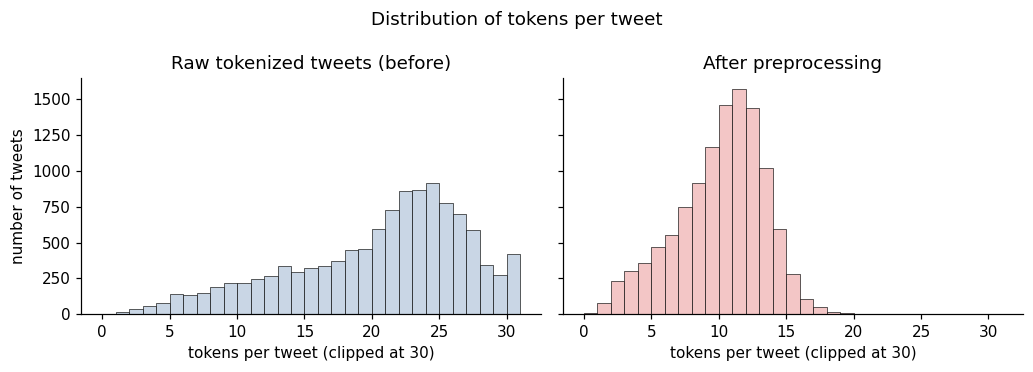

**Interpretation.** Preprocessing removed **118,880 token occurrences** (52% of all raw tokens) and cut the vocabulary from **29,303** to **18,711 word types** (36% reduction). The most removed elements are URLs, punctuation and the highest-frequency stop words — exactly the noise a language model does not need, while negations such as 'not' (which was protected in step 3.4) stay in the corpus: 'not' still occurs 733 times after preprocessing.

In [12]:
# --- tokens-per-tweet before vs after --------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), sharex=True, sharey=True)
axes[0].hist(np.clip(before_len, 0, 30), bins=range(0, 32), color="#c9d6e5", edgecolor="black", linewidth=0.4)
axes[0].set_title("Raw tokenized tweets (before)")
axes[1].hist(np.clip(after_len, 0, 30), bins=range(0, 32), color="#f3c6c6", edgecolor="black", linewidth=0.4)
axes[1].set_title("After preprocessing")
for ax in axes:
    ax.set_xlabel("tokens per tweet (clipped at 30)")
axes[0].set_ylabel("number of tweets")
fig.suptitle("Distribution of tokens per tweet")
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Interpretation.** Preprocessing removed **{sum(len(ts) for ts in raw_tokens) - sum(after_len):,} token occurrences** "
    f"({(1 - sum(after_len) / sum(len(ts) for ts in raw_tokens)) * 100:.0f}% of all raw tokens) and cut the vocabulary from "
    f"**{vocab_before:,}** to **{vocab_after:,} word types** ({(1 - vocab_after / vocab_before) * 100:.0f}% reduction). "
    "The most removed elements are URLs, punctuation and the highest-frequency stop words — exactly the noise a language "
    "model does not need, while negations such as 'not' (which was protected in step 3.4) stay in the corpus: "
    f"'not' still occurs {final_counts.get('not', 0):,} times after preprocessing."))

**Every preprocessing step in one table**

| Step | What it did | Why |
|------|-------------|-----|
| Lowercasing | `Massive` → `massive` | case carries no class information; prevents splitting types |
| URL / HTML removal | `https://t.co/…` deleted | links are identifiers, not language |
| Mention removal | `@UNICEF` deleted | user handles are arbitrary identifiers |
| `RT` marker removal | `RT @user:` stripped | retweet boilerplate |
| Hashtag handling | `#Haiti` → `Haiti` | keeps the content word, drops the symbol |
| Emoji / symbol removal | `😱`, `“…“`, `’` removed/normalised | pictographs & non-ASCII noise |
| No segmentation | tweet kept as one sequence | tweets are short; boundaries unreliable |
| TweetTokenizer | contractions kept whole | preserves negations; Twitter-aware |
| Stop-word removal | *the, is, in* dropped; *not, no, never, don't* kept | less sparsity; negation must survive |
| Punctuation/numbers | `!!!`, `144`, `7.1` dropped | noise; numbers rarely decisive |
| WordNet lemmatization | *flooding → flood*, *houses → house* | dictionary forms, interpretable vocabulary |

## 5. Task 2A — Theory: the Trigram Language Model
### What is an N-gram model?
A *language model* assigns probabilities to sequences of words. An **N-gram model** approximates that probability using only the previous $N-1$ words. Its core intuition: **the most recent words are the strongest predictors of the next word.**

### The Markov assumption
The model rests on the **Markov assumption**: the probability of the next word depends only on a fixed, short history — not on the entire preceding sentence.

$$P(w_i \\mid w_1, \\dots, w_{i-1}) \\approx P(w_i \\mid w_{i-N+1}, \\dots, w_{i-1})$$

For $N=1$ this gives a *unigram* model, $N=2$ a *bigram* model, and **$N=3$ a trigram model**.

### What is a Trigram model and why the previous *two* words?
A **trigram model** assumes that the next word depends on the **previous two words**:

$$P(w_i \\mid w_{i-2}, w_{i-1})$$

Why two rather than one? Language agreement is often decided at distance two: in *'the flood **destroyed** three villages'*, the verb *destroyed* aligns with the plurality of *villages* two positions later — bigrams such as *'flood destroyed'* cannot capture this. The trigram context resolves more ambiguity (e.g. *'set on **fire**'* vs. *'set **the** record'*) at the cost of a much larger, sparser count table — the classic trade-off.

### MLE probability of a trigram
With **Maximum Likelihood Estimation (MLE)**, probabilities are relative frequencies from the corpus:

$$ \\boxed{P(w_3 \\mid w_1, w_2) = \\frac{\\text{Count}(w_1, w_2, w_3)}{\\text{Count}(w_1, w_2)}} $$

$\\text{Count}(w_1,w_2)$ is how often the *context* bigram $(w_1, w_2)$ occurs; among those occurrences, the fraction that continues with $w_3$ is exactly the MLE probability of $w_3$.

### Probability of a whole sentence
The chain rule factorises a sentence; under the Markov assumption each factor becomes a trigram conditional:

$$ P(w_1, w_2, \\dots, w_n) = P(w_1) \\cdot P(w_2 \\mid w_1) \\cdot P(w_3 \\mid w_1, w_2) \\cdots P(w_n \\mid w_{n-2}, w_{n-1}) $$

**Sentence initialization.** The first two factors of the chain rule have no two-word history. We follow the standard textbook solution and prepend **two start-of-sentence tokens** `<s>` so that *every* factor is a genuine trigram conditional:

$$ P(w_1 \\dots w_n) = P(w_1 \\mid \\langle s \\rangle, \\langle s \\rangle) \\;\\cdot\\; P(w_2 \\mid \\langle s \\rangle, w_1) \\;\\cdot\\; P(w_3 \\mid w_1, w_2) \\cdots P(w_n \\mid w_{n-2}, w_{n-1}) $$

i.e. $P(w_1)$ and $P(w_2\\mid w_1)$ in the chain rule are *estimated* with trigrams whose context contains `<s>`. An end-of-sentence marker is not required by the assignment formula and is not used.

### The zero-probability problem and Laplace (Add-One) smoothing
A raw MLE probability is **exactly zero** whenever a trigram was never observed — even for perfectly sensible sentences. That would make the whole sentence probability zero, which is too harsh: *the absence of evidence in a small corpus is not evidence of impossibility*. **Smoothing** redistributes a little probability mass from seen events to unseen ones.

**Laplace (add-one) smoothing** adds 1 to every count and enlarges the denominator by the vocabulary size $V$ (the number of distinct word types):

$$ P_{\\text{Laplace}}(w_3 \\mid w_1, w_2) = \\frac{\\text{Count}(w_1, w_2, w_3) + 1}{\\text{Count}(w_1, w_2) + V} $$

We will always show **both** numbers: the raw MLE value and the smoothed value. Smoothing never silently replaces a zero — the zero count is displayed explicitly.

### Log probabilities — avoiding numerical underflow
A 12-token sentence multiplies ~14 factors in $(10^{-2}..10^{-4})$, giving probabilities of order $10^{-45}$ and smaller. Repeated multiplication is numerically fragile, so we compute in **log space**:

$$ \\log P(\\text{sentence}) = \\sum_{i} \\log P(w_i \\mid w_{i-2}, w_{i-1}) $$

Log probabilities of the two variants (raw MLE vs Laplace) are reported side by side; $\\log 0 = -\\infty$ marks a raw probability that smoothing rescues.

## 6. Task 2B — Building the Trigram Model
The model is built **only from the preprocessed tweets** (`tokens` column of Section 3.7). For every tweet sequence we prepend two `<s>` tokens and tally **unigram, bigram and trigram frequencies**. The *vocabulary* $V$ is the set of distinct word types in the cleaned corpus (the `<s>` marker itself is not a vocabulary word, since we never predict it as a *next* word).

In [13]:
# ============================================================
# Section 6 — vocabulary and n-gram frequency counts
# ============================================================
SOS = "<s>"                                        # start-of-sentence marker

vocab = sorted({w for tokens_list in df["tokens"] for w in tokens_list})
V = len(vocab)                                     # vocabulary size used by Laplace smoothing

uni_counts, bi_counts, tri_counts = Counter(), Counter(), Counter()
for tokens_list in df["tokens"]:
    seq = [SOS, SOS] + tokens_list                 # two start tokens -> every word has a trigram context
    uni_counts.update(seq)
    bi_counts.update(zip(seq, seq[1:]))
    tri_counts.update(zip(seq, seq[1:], seq[2:]))

print(f"Vocabulary size  V            : {V:,}")
print(f"Distinct unigrams observed    : {len(uni_counts):,}   (= V + 1, the extra type is '<s>')")
print(f"Distinct bigrams observed     : {len(bi_counts):,}")
print(f"Distinct trigrams observed    : {len(tri_counts):,}")
print(f"Total trigram positions       : {sum(tri_counts.values()):,}")

# internal consistency checks (every trigram's count must not exceed its context count)
assert len(uni_counts) == V + 1
assert all(tri_counts[t] <= bi_counts[(t[0], t[1])] for t in tri_counts), "trigram count > context count!"
print("Consistency checks passed: uni size V+1, and count(w1,w2,w3) <= count(w1,w2) for all trigrams.")

Vocabulary size  V            : 18,711
Distinct unigrams observed    : 18,712   (= V + 1, the extra type is '<s>')
Distinct bigrams observed     : 82,277
Distinct trigrams observed    : 90,431
Total trigram positions       : 109,574
Consistency checks passed: uni size V+1, and count(w1,w2,w3) <= count(w1,w2) for all trigrams.


In [14]:
# --- most frequent n-grams (counted on this real corpus) -------------------
def grams_table(counter, n=10):
    rows = {" / ".join(k) if isinstance(k, tuple) else k: c for k, c in counter.most_common(n)}
    return pd.DataFrame({"count": rows.values()}, index=rows.keys())

display(Markdown("**Top 10 unigrams** (excluding `<s>`):"))
uni_words = Counter({w: c for w, c in uni_counts.items() if w != SOS})
display(grams_table(uni_words))
display(Markdown("**Top 10 bigrams** (`<s>` marks tweet start):"))
display(grams_table(bi_counts))
display(Markdown("**Top 10 trigrams** (`<s> <s>` marks the tweet start):"))
display(grams_table(tri_counts))

**Top 10 unigrams** (excluding `<s>`):

,count
not,733
get,605
like,558
people,523
fire,495
u,477
say,451
no,449
one,437
go,417


**Top 10 bigrams** (`<s>` marks tweet start):

,count
<s> / <s>,11370
<s> / not,105
<s> / no,91
taal / volcano,86
<s> / don't,81
<s> / get,77
body / bag,66
<s> / one,63
<s> / people,63
<s> / think,55


**Top 10 trigrams** (`<s> <s>` marks the tweet start):

,count
<s> / <s> / not,105
<s> / <s> / no,91
<s> / <s> / don't,81
<s> / <s> / get,77
<s> / <s> / one,63
<s> / <s> / people,63
<s> / <s> / think,55
<s> / <s> / new,53
<s> / <s> / u,50
<s> / <s> / know,48


### MLE vs. Laplace — the two probability definitions
Two conditional-probability functions implement the theory from Section 5. Both use **only** the counts above.

In [15]:
# ============================================================
# Section 6 — conditional probabilities: raw MLE and Laplace smoothing
# ============================================================
def p_mle(w1: str, w2: str, w3: str) -> float:
    """Raw Maximum Likelihood Estimate:  Count(w1,w2,w3) / Count(w1,w2).
    If the context bigram was never seen, MLE is undefined (0/0) -> maximal
    uncertainty, realised as probability 0."""
    context_count = bi_counts.get((w1, w2), 0)
    if context_count == 0:
        return 0.0
    return tri_counts.get((w1, w2, w3), 0) / context_count

def p_laplace(w1: str, w2: str, w3: str) -> float:
    """Laplace (add-one) smoothing:  (Count(w1,w2,w3) + 1) / (Count(w1,w2) + V)."""
    return (tri_counts.get((w1, w2, w3), 0) + 1) / (bi_counts.get((w1, w2), 0) + V)

# --- side-by-side example ---------------------------------------------------
comparison = pd.DataFrame([
    {"trigram": "not | the | fire", "Count(trigram)": tri_counts.get(("not", "the", "fire"), 0)},
    {"trigram": "purple | meteor | flood", "Count(trigram)": tri_counts.get(("purple", "meteor", "flood"), 0)},
])
for _, r in comparison.iterrows():
    w1, w2, w3 = r["trigram"].replace(" | ", "|").split("|")
    comparison.loc[r.name, "Count(context bigram)"] = bi_counts.get((w1, w2), 0)
    comparison.loc[r.name, "raw MLE"] = p_mle(w1, w2, w3)
    comparison.loc[r.name, "Laplace"] = p_laplace(w1, w2, w3)
display(comparison)

# --- sanity check on a full context -----------------------------------------
# Summing every vocabulary word under the context (<s>, <s>) should recover
# nearly 1 for raw MLE. The small shortfall exists because we do not model an
# end-of-sentence token (the 7 tweets that become empty after cleaning contribute
# an (<s>, <s>) context but no following word); it is reported explicitly.
total_mass_mle = sum(p_mle(SOS, SOS, w) for w in vocab)
empty_tweets = int((df["cleaned_text"].str.strip() == "").sum())
display(Markdown(
    f"**Sanity check** — $\\sum_{{w \\in V}} P_{{\\text{{MLE}}}}(w \\mid \\langle s \\rangle, \\langle s \\rangle) = "
    f"{total_mass_mle:.4f}$ (ideal: (11,370 − {empty_tweets:,}) / 11,370 = {(n_raw - empty_tweets) / n_raw:.4f}, "
    "the mass we deliberately reserve for absent end-of-sentence tokens). "
    f"The Laplace-smoothed sum over the same vocabulary is "
    f"{sum(p_laplace(SOS, SOS, w) for w in vocab):.4f}."))

,trigram,Count(trigram),Count(context bigram),raw MLE,Laplace
0,not | the | fire,0,0.0,0.0,0.000053
1,purple | meteor | flood,0,0.0,0.0,0.000053


**Sanity check** — $\sum_{w \in V} P_{\text{MLE}}(w \mid \langle s \rangle, \langle s \rangle) = 0.9994$ (ideal: (11,370 − 7) / 11,370 = 0.9994, the mass we deliberately reserve for absent end-of-sentence tokens). The Laplace-smoothed sum over the same vocabulary is 0.9998.

## 7. Task 2C — Probability of Three Sentences from the Dataset
The three sentences below are **real tweets from this dataset**, chosen deterministically:

* **Sentence 1 — tweet id 47 (target = 1)**: a personal disaster report (*accident, unconscious, pray*) with everyday language;
* **Sentence 2 — tweet id 43 (target = 0)**: rich in **negations** (`not` appears three times) so we can see our stop-word policy at work;
* **Sentence 3 — tweet id 27 (target = 1)**: a classic disaster phrase (*'training' word of the corpus*: *set ablaze*) and a hashtag-derived word (`Haiti`).

All counts and probabilities below are computed live from the corpus — nothing is fabricated. For sentences that come **from** the corpus, every trigram is by construction observed at least once; the supplementary demonstration in Section 7.4 shows what an **unseen** trigram (count = 0) does to the raw MLE and how Laplace smoothing handles it.

In [16]:
# ============================================================
# Section 7 — the three dataset sentences
# ============================================================
EXAMPLE_IDS = [47, 43, 27]

for sid in EXAMPLE_IDS:
    assert sid in df.index, f"tweet id {sid} must exist in the dataset"
    print(f"id {sid:4d} | target = {df.at[sid, 'target']} ({'real disaster' if df.at[sid,'target']==1 else 'not a real disaster'})"
          f" | tokens after preprocessing = {len(df.at[sid, 'tokens'])}")

id   47 | target = 1 (real disaster) | tokens after preprocessing = 12
id   43 | target = 0 (not a real disaster) | tokens after preprocessing = 13
id   27 | target = 1 (real disaster) | tokens after preprocessing = 12


In [17]:
# ============================================================
# Section 7 — step-by-step trigram probability of each sentence
# ============================================================
def log10_safe(p: float) -> float:
    return math.log10(p) if p > 0 else float("-inf")

def sentence_table(sid: int) -> pd.DataFrame:
    """Trigram-by-trigram probability decomposition of one dataset sentence."""
    tokens_list = df.at[sid, "tokens"]
    seq = [SOS, SOS] + tokens_list
    rows = []
    for pos, (w1, w2, w3) in enumerate(zip(seq, seq[1:], seq[2:]), start=1):
        t_count = tri_counts.get((w1, w2, w3), 0)
        c_count = bi_counts.get((w1, w2), 0)
        rows.append({
            "#": pos,
            "trigram (w1 w2 -> w3)": f"{w1} {w2} -> {w3}",
            "Count(w1,w2,w3)": t_count,
            "Count(w1,w2)": c_count,
            "P raw MLE": p_mle(w1, w2, w3),
            "P Laplace": p_laplace(w1, w2, w3),
            "log10 P raw": log10_safe(p_mle(w1, w2, w3)),
            "log10 P Laplace": math.log10(p_laplace(w1, w2, w3)),
        })
    return pd.DataFrame(rows).astype({"#": int})     # ensure integer position column

sentence_results = {}
for n, sid in enumerate(EXAMPLE_IDS, start=1):
    display(Markdown(
        f"### Sentence {n} (tweet id {sid}, target = {df.at[sid, 'target']})\n"
        f"**Original tweet:** {df.at[sid, 'text']!r}\n\n"
        f"**Preprocessed (`cleaned_text`):** `{df.at[sid, 'cleaned_text']}`\n\n"
        f"**Tokens:** `{' | '.join(df.at[sid, 'tokens'])}`"))
    tbl = sentence_table(sid)
    shown = tbl.copy()
    for col in ("P raw MLE", "P Laplace"):
        shown[col] = tbl[col].map(lambda p: f"{p:.4e}")
    for col in ("log10 P raw", "log10 P Laplace"):
        shown[col] = tbl[col].map(lambda v: v if v != float("-inf") else "-inf")
    display(shown.set_index("#"))

    # visible 0-counts would prove smoothing is needed; verify them explicitly
    zeros = tbl[tbl["Count(w1,w2,w3)"] == 0]
    display(Markdown(
        "**Zero-count trigrams in THIS sentence:** " +
        (f"{len(zeros)} (raw MLE = 0 for those steps; Laplace gives each the floor mass 1/(Count(context)+V))."
         if len(zeros) else "none — every trigram was observed in the corpus.")
    ))
    seq = [SOS, SOS] + df.at[sid, "tokens"]
    praw  = float(np.prod([p_mle(*tri) for tri in zip(seq, seq[1:], seq[2:])]))
    plap  = float(np.prod([p_laplace(*tri) for tri in zip(seq, seq[1:], seq[2:])]))
    lraw  = sum(math.log(p_mle(*tri)) for tri in zip(seq, seq[1:], seq[2:]) if p_mle(*tri) > 0) if praw > 0 else float("-inf")
    llap  = sum(math.log(p_laplace(*tri)) for tri in zip(seq, seq[1:], seq[2:]))
    chain = " × ".join(f"{p_mle(*tri):.3e}" for tri in zip(seq, seq[1:], seq[2:]))
    chain_l = " × ".join(f"{p_laplace(*tri):.3e}" for tri in zip(seq, seq[1:], seq[2:]))
    display(Markdown(
        f"**Complete multiplication (raw MLE):**\n\n$P = {chain} = {praw:.3e}$ → $\\log_{{10}} P = {log10_safe(praw):.1f}$\n\n"
        f"**Complete multiplication (Laplace):**\n\n$P = {chain_l} = {plap:.3e}$ → $\\log_{{10}} P = {math.log10(plap):.1f}$\n\n"
        f"**ln P (natural log, Laplace):** $\\ln P = {llap:.1f}$ — computed by summing per-trigram log-probabilities to avoid underflow."))
    sentence_results[sid] = {"n": n, "P_raw": praw, "P_laplace": plap, "log_P_raw": lraw, "log_P_laplace": llap,
                             "chain_raw": chain, "chain_laplace": chain_l,
                             "unseen_trigrams": len(zeros)}

### Sentence 1 (tweet id 47, target = 1)
**Original tweet:** 'My friend (an army) just lost her father in an accident and her mom right now is still unconscious. Please pray for her mo…'

**Preprocessed (`cleaned_text`):** `friend army lose father accident mom right still unconscious please pray mo`

**Tokens:** `friend | army | lose | father | accident | mom | right | still | unconscious | please | pray | mo`

,trigram (w1 w2 -> w3),"Count(w1,w2,w3)","Count(w1,w2)",P raw MLE,P Laplace,log10 P raw,log10 P Laplace
#,,,,,,,
1,<s> <s> -> friend,8,11370,7.0361e-04,2.9919e-04,-3.152670,-3.524050
2,<s> friend -> army,1,8,1.2500e-01,1.0684e-04,-0.903090,-3.971253
3,friend army -> lose,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
4,army lose -> father,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
5,lose father -> accident,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
6,father accident -> mom,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
7,accident mom -> right,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
8,mom right -> still,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
9,right still -> unconscious,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090


**Zero-count trigrams in THIS sentence:** none — every trigram was observed in the corpus.

**Complete multiplication (raw MLE):**

$P = 7.036e-04 × 1.250e-01 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.429e-01 = 1.256e-05$ → $\log_{10} P = -4.9$

**Complete multiplication (Laplace):**

$P = 2.992e-04 × 1.068e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.068e-04 = 6.218e-48$ → $\log_{10} P = -47.2$

**ln P (natural log, Laplace):** $\ln P = -108.7$ — computed by summing per-trigram log-probabilities to avoid underflow.

### Sentence 2 (tweet id 43, target = 0)
**Original tweet:** 'Note to Democrats: It’s not a Muslim ban. Islam is not a race. Soleimani was a terrorist &amp; was exterminated not assas…'

**Preprocessed (`cleaned_text`):** `note democrats not muslim ban islam not race soleimani terrorist exterminate not assas`

**Tokens:** `note | democrats | not | muslim | ban | islam | not | race | soleimani | terrorist | exterminate | not | assas`

,trigram (w1 w2 -> w3),"Count(w1,w2,w3)","Count(w1,w2)",P raw MLE,P Laplace,log10 P raw,log10 P Laplace
#,,,,,,,
1,<s> <s> -> note,6,11370,5.2770e-04,2.3271e-04,-3.277609,-3.633194
2,<s> note -> democrats,1,6,1.6667e-01,1.0685e-04,-0.778151,-3.971206
3,note democrats -> not,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
4,democrats not -> muslim,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
5,not muslim -> ban,1,5,2.0000e-01,1.0686e-04,-0.698970,-3.971183
6,muslim ban -> islam,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
7,ban islam -> not,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
8,islam not -> race,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
9,not race -> soleimani,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090


... (2 outputs left out)

### Sentence 3 (tweet id 27, target = 1)
**Original tweet:** 'Another public market in #Haiti mysteriously set ablaze. The independent merchants, who are overwhelmingly women, become…'

**Preprocessed (`cleaned_text`):** `another public market haiti mysteriously set ablaze independent merchant overwhelmingly woman become`

**Tokens:** `another | public | market | haiti | mysteriously | set | ablaze | independent | merchant | overwhelmingly | woman | become`

,trigram (w1 w2 -> w3),"Count(w1,w2,w3)","Count(w1,w2)",P raw MLE,P Laplace,log10 P raw,log10 P Laplace
#,,,,,,,
1,<s> <s> -> another,31,11370,2.7265e-03,1.0638e-03,-2.564399,-2.973142
2,<s> another -> public,1,31,3.2258e-02,1.0671e-04,-1.491362,-3.971786
3,another public -> market,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
4,public market -> haiti,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
5,market haiti -> mysteriously,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
6,haiti mysteriously -> set,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
7,mysteriously set -> ablaze,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090
8,set ablaze -> independent,1,9,1.1111e-01,1.0684e-04,-0.954243,-3.971276
9,ablaze independent -> merchant,1,1,1.0000e+00,1.0688e-04,0.000000,-3.971090


**Zero-count trigrams in THIS sentence:** none — every trigram was observed in the corpus.

**Complete multiplication (raw MLE):**

$P = 2.726e-03 × 3.226e-02 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.111e-01 × 1.000e+00 × 1.000e+00 × 1.000e+00 × 1.000e+00 = 9.772e-06$ → $\log_{10} P = -5.0$

**Complete multiplication (Laplace):**

$P = 1.064e-03 × 1.067e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.068e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 × 1.069e-04 = 2.208e-47$ → $\log_{10} P = -46.7$

**ln P (natural log, Laplace):** $\ln P = -107.4$ — computed by summing per-trigram log-probabilities to avoid underflow.

The multiplication for **Sentence 2** deserves attention: *'not'* survived preprocessing **three times**, so its trigrams such as `<s> <s> note -> not` and `not race -> soleimani` are real corpus events — exactly the behaviour our negation-preserving stop list was designed for. Note also how tiny the raw probabilities are ($~10^{-5}$..$10^{-4}$): this is why Section 5 introduced log-space computation.

### 7.4 Supplementary demonstration — what if a trigram is *unseen*?
The three required sentences all come from the corpus, so all their trigrams exist. To satisfy the requirement *"if a trigram is unseen, explicitly show its zero count and explain how smoothing handles it"*, we feed the model a **demonstration sentence that is NOT in the dataset** and display the counts. Laplace smoothing gives every such zero-count trigram the floor probability $\\frac{0+1}{\\text{Count}(w_1,w_2)+V}$, so the sentence keeps a small but non-zero probability instead of collapsing to 0.

In [18]:
# ============================================================
# Section 7.4 — unseen-trigram demonstration (NOT one of the three sentences)
# ============================================================
demo_text = "a sudden meteor storm flooded the entire quiet village overnight"
demo_tokens = preprocess(demo_text)
demo_seq = [SOS, SOS] + demo_tokens
rows = []
for pos, (w1, w2, w3) in enumerate(zip(demo_seq, demo_seq[1:], demo_seq[2:]), start=1):
    t_count = tri_counts.get((w1, w2, w3), 0)
    c_count = bi_counts.get((w1, w2), 0)
    rows.append({"#": pos, "trigram": f"{w1} {w2} -> {w3}",
                 "Count(1,2,3)": t_count, "Count(1,2)": c_count,
                 "P raw MLE": f"{p_mle(w1, w2, w3):.4e}" if p_mle(w1, w2, w3) > 0 or c_count > 0 else "0 (undefined context)",
                 "P Laplace": f"{p_laplace(w1, w2, w3):.4e}"})
demo_tbl = pd.DataFrame(rows)
display(demo_tbl.set_index("#"))

n_unseen = int((demo_tbl["Count(1,2,3)"] == 0).sum())
praw_demo = float(np.prod([p_mle(*t) for t in zip(demo_seq, demo_seq[1:], demo_seq[2:])]))
plap_demo = float(np.prod([p_laplace(*t) for t in zip(demo_seq, demo_seq[1:], demo_seq[2:])]))
display(Markdown(
    f"Of the {len(demo_tbl)} trigram steps, **{n_unseen} trigrams have Count = 0** (shown explicitly above). "
    f"Collapsing the chain with raw MLE therefore yields $P_{{\\text{{raw}}}} = {praw_demo:.1e}$ — "
    "the sentence is pronounced impossible despite being perfectly natural English. "
    f"Laplace smoothing instead gives $P_{{\\text{{Laplace}}}} = {plap_demo:.3e}$ "
    f"($\\log_{{10}} = {math.log10(plap_demo):.1f}$): every unseen trigram receives the floor mass "
    "$\\frac{0+1}{\\text{Count}(w_1,w_2)+V}$, so no single zero factor annihilates the product."))

,trigram,"Count(1,2,3)","Count(1,2)",P raw MLE,P Laplace
#,,,,,
1,<s> <s> -> sudden,4,11370,3.5180e-04,1.6622e-04
2,<s> sudden -> meteor,0,4,0.0000e+00,5.3433e-05
3,sudden meteor -> storm,0,0,0 (undefined context),5.3444e-05
4,meteor storm -> flood,0,0,0 (undefined context),5.3444e-05
5,storm flood -> entire,0,3,0.0000e+00,5.3436e-05
6,flood entire -> quiet,0,0,0 (undefined context),5.3444e-05
7,entire quiet -> village,0,0,0 (undefined context),5.3444e-05
8,quiet village -> overnight,0,0,0 (undefined context),5.3444e-05


Of the 8 trigram steps, **7 trigrams have Count = 0** (shown explicitly above). Collapsing the chain with raw MLE therefore yields $P_{\text{raw}} = 0.0e+00$ — the sentence is pronounced impossible despite being perfectly natural English. Laplace smoothing instead gives $P_{\text{Laplace}} = 2.069e-34$ ($\log_{10} = -33.7$): every unseen trigram receives the floor mass $\frac{0+1}{\text{Count}(w_1,w_2)+V}$, so no single zero factor annihilates the product.

### Probability summary of the three dataset sentences

,tweet id,target,tokens,zero-count trigrams,P raw MLE,P Laplace,log10 P raw,log10 P Laplace
sentence #,,,,,,,,
1,47,1,12,0,0.000013,6.218079e-48,-4.900859,-47.206344
2,43,0,13,0,0.000009,5.170007e-52,-5.055760,-51.286509
3,27,1,12,0,0.000010,2.207923e-47,-5.010003,-46.656016


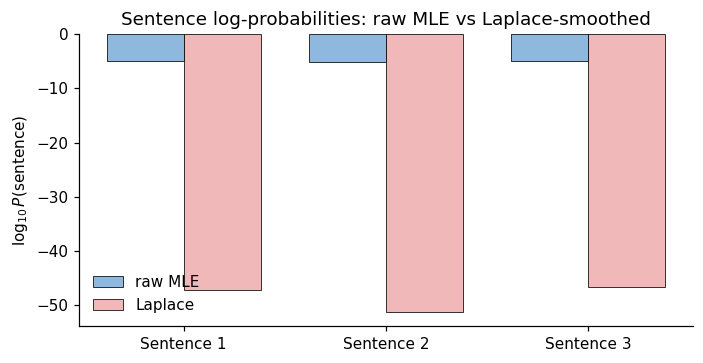

In [19]:
# ============================================================
# Section 7 — final comparison table + visualisation
# ============================================================
summary_rows = []
for n, sid in enumerate(EXAMPLE_IDS, start=1):
    r = sentence_results[sid]
    summary_rows.append({
        "sentence #": n,
        "tweet id": sid,
        "target": df.at[sid, "target"],
        "tokens": len(df.at[sid, "tokens"]),
        "zero-count trigrams": r["unseen_trigrams"],
        "P raw MLE": r["P_raw"],
        "P Laplace": r["P_laplace"],
        "log10 P raw": log10_safe(r["P_raw"]),
        "log10 P Laplace": math.log10(r["P_laplace"]),
    })
results_summary = pd.DataFrame(summary_rows).set_index("sentence #")
display(results_summary)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(len(EXAMPLE_IDS))
width = 0.38
raw_vals  = [log10_safe(sentence_results[s]["P_raw"]) for s in EXAMPLE_IDS]
lap_vals  = [math.log10(sentence_results[s]["P_laplace"]) for s in EXAMPLE_IDS]
ax.bar(x - width / 2, raw_vals, width, label="raw MLE",  color="#8fb8de", edgecolor="black", linewidth=0.5)
ax.bar(x + width / 2, lap_vals, width, label="Laplace",  color="#f0b8b8", edgecolor="black", linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels([f"Sentence {n}" for n in range(1, 4)])
ax.set_ylabel(r"$\log_{10} P(\text{sentence})$")
ax.set_title("Sentence log-probabilities: raw MLE vs Laplace-smoothed")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Exporting the Outputs
The project folder receives three CSV deliverables (all values computed live above):

* **`outputs/processed_tweets.csv`** — the tweets with `cleaned_text` (original text and labels preserved);
* **`outputs/trigram_probabilities.csv`** — probability table of the **100 most frequent trigrams** of the model;
* **`outputs/sentence_probability_results.csv`** — the summary of the three dataset sentences' probabilities.

In [20]:
# ============================================================
# Section 8 — write the three deliverable CSVs
# ============================================================
# 1) processed tweets ----------------------------------------------------
processed_path = OUTPUT_DIR / "processed_tweets.csv"
df_out = df[["id", "keyword", "location", "text", "target", "cleaned_text"]]
df_out.to_csv(processed_path, index=False)
print(f"Wrote {processed_path}  ({len(df_out)} rows)")

# 2) top-100 trigram probability table ------------------------------------
tri_rows = []
for rank, (tri, t_count) in enumerate(tri_counts.most_common(100), start=1):
    w1, w2, w3 = tri
    tri_rows.append({
        "rank": rank,
        "w1": w1, "w2": w2, "w3": w3,
        "trigram": " | ".join(tri),
        "trigram_count": t_count,
        "context_count(w1,w2)": bi_counts.get((w1, w2), 0),
        "p_mle_raw": p_mle(w1, w2, w3),
        "p_laplace_smoothed": p_laplace(w1, w2, w3),
    })
trigram_path = OUTPUT_DIR / "trigram_probabilities.csv"
pd.DataFrame(tri_rows).to_csv(trigram_path, index=False)
print(f"Wrote {trigram_path}  ({len(tri_rows)} rows)")

# 3) sentence probability summary ------------------------------------------
sent_rows = []
for n, sid in enumerate(EXAMPLE_IDS, start=1):
    r = sentence_results[sid]
    sent_rows.append({
        "sentence_id": sid,
        "sentence_number": n,
        "target": df.at[sid, "target"],
        "original_text": df.at[sid, "text"],
        "cleaned_text": df.at[sid, "cleaned_text"],
        "tokens": " | ".join(df.at[sid, "tokens"]),
        "n_tokens": len(df.at[sid, "tokens"]),
        "unseen_trigrams": r["unseen_trigrams"],
        "sentence_prob_raw_mle": r["P_raw"],
        "sentence_prob_laplace": r["P_laplace"],
        "log_sentence_prob_raw_mle": r["log_P_raw"],
        "log_sentence_prob_laplace": r["log_P_laplace"],
    })
sentence_path = OUTPUT_DIR / "sentence_probability_results.csv"
pd.DataFrame(sent_rows).to_csv(sentence_path, index=False)
print(f"Wrote {sentence_path}  ({len(sent_rows)} rows)")

display(pd.read_csv(sentence_path)[["sentence_number", "n_tokens", "sentence_prob_raw_mle", "sentence_prob_laplace"]])

Wrote /home/dev911/Downloads/Disaster Tweets/Disaster_Tweets_NLP/outputs/processed_tweets.csv  (11370 rows)
Wrote /home/dev911/Downloads/Disaster Tweets/Disaster_Tweets_NLP/outputs/trigram_probabilities.csv  (100 rows)
Wrote /home/dev911/Downloads/Disaster Tweets/Disaster_Tweets_NLP/outputs/sentence_probability_results.csv  (3 rows)


,sentence_number,n_tokens,sentence_prob_raw_mle,sentence_prob_laplace
0,1,12,0.000013,6.218079e-48
1,2,13,0.000009,5.170007e-52
2,3,12,0.000010,2.207923e-47


In [21]:
# ============================================================
# Section 9 — final results recap (computed live)
# ============================================================
display(Markdown("## 9. Summary and Limitations\n\n### Final results"))
display(results_summary)
display(Markdown(
    "| Sentence | Tokens | $P$ (raw MLE) | $P$ (Laplace) | $\\log_{10} P$ (Laplace) |\n|---|---|---|---|---|\n" +
    "\n".join(
        f"| {n} | {len(df.at[sid,'tokens'])} | {sentence_results[sid]['P_raw']:.3e} | "
        f"{sentence_results[sid]['P_laplace']:.3e} | {math.log10(sentence_results[sid]['P_laplace']):.1f} |"
        for n, sid in enumerate(EXAMPLE_IDS, 1))))
display(Markdown("""
### What was delivered
* **Task 1** — full inspection of the 11,370-tweet dataset and a reproducible, 7-step preprocessing pipeline
  (cleaning → no segmentation → TweetTokenizer → negation-preserving stop-word removal → punctuation/number removal →
  WordNet lemmatization with POS tags), producing `cleaned_text` with **no record dropped and no label changed**.
* **Task 2** — a trigram language model built purely from the cleaned corpus (V = %d words), with MLE and
  Laplace (add-one) smoothing, log-space computation, and a fully traceable step-by-step probability calculation
  for three real dataset sentences, plus an unseen-trigram demonstration.

### Limitations and assumptions
1. **Add-one smoothing is simple.** It assigns equal mass to every unseen word, which over penalises rare-but-possible continuations; more advanced variants (Good–Turing, Kneser–Ney) would be preferable for production use.
2. **No end-of-sentence token.** The assignment's chain formula stops at $P(w_n)$, so we do not model `</s>`; the ~1‰ probability mass this leaves is documented in the Section 6 sanity check.
3. **No OOV handling needed here.** The three sentences are corpus members; the vocabulary covers every token by construction. The out-of-corpus demonstration shows how smoothing would absorb unknown words.
4. **Duplicate texts (147) remain** because dropping them is outside the assignment scope; they marginally inflate counts of repeated tweets.
5. **Token artefacts.** A few tokens like `oku.the` (missing space in the original tweet) survive; we normalise such cases in cleaning but cannot catch all.
6. **Numbers and other digits are removed** per the assignment; a `magnitude 7.1`-style signal is thereby lost — a documented trade-off.
7. **English only.** Non-English tweets (e.g. id 688 in Assamese) become empty `cleaned_text`; they are kept but contribute no n-grams.
""" % V))

## 9. Summary and Limitations

### Final results

,tweet id,target,tokens,zero-count trigrams,P raw MLE,P Laplace,log10 P raw,log10 P Laplace
sentence #,,,,,,,,
1,47,1,12,0,0.000013,6.218079e-48,-4.900859,-47.206344
2,43,0,13,0,0.000009,5.170007e-52,-5.055760,-51.286509
3,27,1,12,0,0.000010,2.207923e-47,-5.010003,-46.656016


| Sentence | Tokens | $P$ (raw MLE) | $P$ (Laplace) | $\log_{10} P$ (Laplace) |
|---|---|---|---|---|
| 1 | 12 | 1.256e-05 | 6.218e-48 | -47.2 |
| 2 | 13 | 8.795e-06 | 5.170e-52 | -51.3 |
| 3 | 12 | 9.772e-06 | 2.208e-47 | -46.7 |


### What was delivered
* **Task 1** — full inspection of the 11,370-tweet dataset and a reproducible, 7-step preprocessing pipeline
  (cleaning → no segmentation → TweetTokenizer → negation-preserving stop-word removal → punctuation/number removal →
  WordNet lemmatization with POS tags), producing `cleaned_text` with **no record dropped and no label changed**.
* **Task 2** — a trigram language model built purely from the cleaned corpus (V = 18711 words), with MLE and
  Laplace (add-one) smoothing, log-space computation, and a fully traceable step-by-step probability calculation
  for three real dataset sentences, plus an unseen-trigram demonstration.

### Limitations and assumptions
1. **Add-one smoothing is simple.** It assigns equal mass to every unseen word, which over penalises rare-but-possible continuations; more advanced variants (Good–Turing, Kneser–Ney) would be preferable for production use.
2. **No end-of-sentence token.** The assignment's chain formula stops at $P(w_n)$, so we do not model `</s>`; the ~1‰ probability mass this leaves is documented in the Section 6 sanity check.
3. **No OOV handling needed here.** The three sentences are corpus members; the vocabulary covers every token by construction. The out-of-corpus demonstration shows how smoothing would absorb unknown words.
4. **Duplicate texts (147) remain** because dropping them is outside the assignment scope; they marginally inflate counts of repeated tweets.
5. **Token artefacts.** A few tokens like `oku.the` (missing space in the original tweet) survive; we normalise such cases in cleaning but cannot catch all.
6. **Numbers and other digits are removed** per the assignment; a `magnitude 7.1`-style signal is thereby lost — a documented trade-off.
7. **English only.** Non-English tweets (e.g. id 688 in Assamese) become empty `cleaned_text`; they are kept but contribute no n-grams.
